# EM 알고리즘 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week04/em_algorithm/lab/em_algorithm.ipynb)

숨은 무리가 있는 데이터에 가우시안 두 개를 맞춘다. E 단계(확률 매기기) 와 M 단계(무게 평균) 를 직접 구현한다.

- **파트 1**: E · M 직접 구현 → 키 24명으로 슬라이드 숫자 재현
- **파트 2**: 올드 페이스풀 간헐천: 분출까지 기다린 시간의 두 무리
- **파트 3**: scikit-learn `GaussianMixture` (2차원) 와 k-means 비교

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

## 슬라이드의 예시 데이터

학년이 지워진 키 명단 24명 (cm). 앞 12명이 초6, 뒤 12명이 중3 이지만 EM 은 이 사실을 쓰지 않는다 (마지막에 채점용으로만 쓴다).

In [ ]:
# Same example as the slides: heights (cm) of 24 students, grade erased
x = np.array([142, 145, 147, 148, 149, 150, 151, 152, 153, 155, 157, 159,     # grade 6 (hidden)
              158, 161, 163, 164, 165, 166, 167, 168, 169, 171, 173, 176],    # grade 9 (hidden)
             dtype=float)
true_grade9 = np.r_[np.zeros(12), np.ones(12)]                              # only for checking at the end
plt.scatter(x, np.zeros_like(x)); plt.yticks([]); plt.xlabel("height (cm)"); plt.show()

**예상 결과**

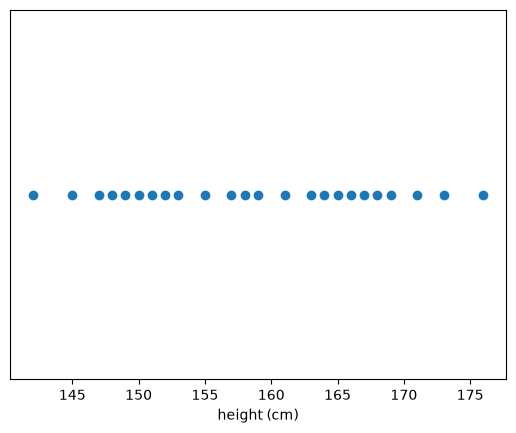

## 파트 1. E 단계와 M 단계

$$\gamma_{ij} = \frac{\pi_j\,\mathcal{N}(x_i;\mu_j,\sigma_j^2)}{\sum_k \pi_k\,\mathcal{N}(x_i;\mu_k,\sigma_k^2)}, \qquad
\mu_j = \frac{\sum_i \gamma_{ij} x_i}{\sum_i \gamma_{ij}}, \quad \sigma_j^2 = \frac{\sum_i \gamma_{ij}(x_i-\mu_j)^2}{\sum_i \gamma_{ij}}, \quad \pi_j = \frac{1}{m}\sum_i \gamma_{ij}$$

In [ ]:
def normal_pdf(x, mu, sd):
    return np.exp(-(x - mu) ** 2 / (2 * sd ** 2)) / (np.sqrt(2 * np.pi) * sd)

def e_step(x, mu, sd, pi):
    p = pi * normal_pdf(x[:, None], mu, sd)              # shape (points, 2): prior x likelihood
    gamma = None  # TODO: normalize each row to sum to 1
    return gamma, np.log(p.sum(axis=1)).sum()

def m_step(x, gamma):
    n = gamma.sum(axis=0)
    mu = None  # TODO: weighted mean
    sd = np.sqrt((gamma * (x[:, None] - mu) ** 2).sum(axis=0) / n)
    pi = None  # TODO: mixing proportions
    return mu, sd, pi

def em(x, mu, sd, pi, iters):
    mu, sd, pi = map(np.array, (mu, sd, pi))
    log_liks = []
    for _ in range(iters):
        gamma, ll = e_step(x, mu, sd, pi)
        log_liks.append(ll)
        mu, sd, pi = m_step(x, gamma)
    gamma, ll = e_step(x, mu, sd, pi)
    log_liks.append(ll)
    return mu, sd, pi, gamma, log_liks

g0, _ = e_step(x, np.array([150.0, 155.0]), np.array([6.0, 6.0]), np.array([0.5, 0.5]))
print("first E step, 153 cm -> grade 9:", round(g0[x == 153][0, 1], 2))
mu1, _, _ = m_step(x, g0)
print("first M step means:", mu1.round(1))
mu, sd, pi, gamma, lls = em(x, [150, 155], [6, 6], [0.5, 0.5], iters=40)
print("after 40 iterations: mu", mu.round(1), "sd", sd.round(1), "pi", pi.round(2))
pred = gamma[:, 1] > 0.5
print("correct:", int((pred == true_grade9).sum()), "/ 24;  157 cm -> grade 9:", round(gamma[x == 157][0, 1], 2))
plt.plot(lls, "o-"); plt.xlabel("iteration"); plt.ylabel("log-likelihood"); plt.show()

**예상 결과**

```
first E step, 153 cm -> grade 9: 0.52
first M step means: [152.3 162.1]
after 40 iterations: mu [149.7 165.4] sd [4.3 5.8] pi [0.43 0.57]
correct: 22 / 24;  157 cm -> grade 9: 0.6
```

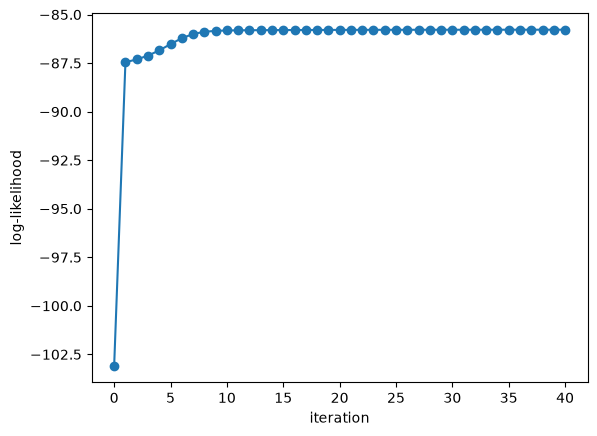

## 파트 2. 올드 페이스풀 간헐천

미국 옐로스톤 국립공원의 간헐천. 272번 분출에 대해 직전 분출에서 다음 분출까지 기다린 시간(분, `waiting`). 처음 실행하면 CSV 를 내려받는다.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/geyser.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/geyser.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/geyser.csv")
df = pd.read_csv("data/geyser.csv")
w = df["waiting"].to_numpy(float)
print(len(df), "eruptions"); print(df.head())

**예상 결과**

```
272 eruptions
   duration  waiting   kind
0     3.600       79   long
1     1.800       54  short
2     3.333       74   long
3     2.283       62  short
4     4.533       85   long
```

In [ ]:
# Same EM code, real data. Start from two guesses.
mu, sd, pi, gamma, lls = em(w, [60, 70], [10, 10], [0.5, 0.5], iters=100)
print("means", mu.round(1), "sds", sd.round(1), "proportions", pi.round(2))
ts = np.linspace(40, 100, 300)
plt.hist(w, bins=30, density=True, alpha=0.4)
mixture = None  # TODO: pi1*N1 + pi2*N2 at every t
plt.plot(ts, mixture, lw=2); plt.xlabel("waiting (min)"); plt.show()

**예상 결과**

```
means [54.6 80.1] sds [5.9 5.9] proportions [0.36 0.64]
```

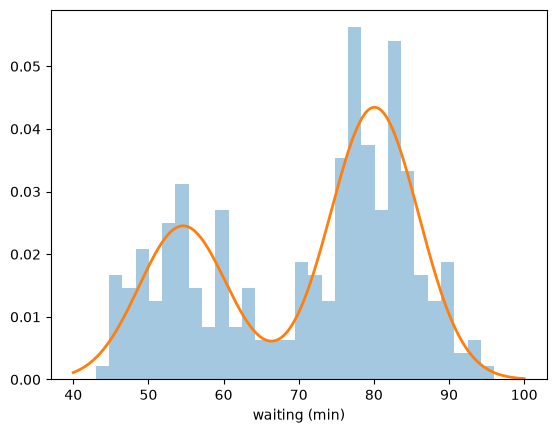

## 파트 3. 2차원: GaussianMixture vs k-means

분출 시간(`duration`) 과 대기 시간(`waiting`) 을 함께 쓴다. 단위가 다르니 표준화한다.

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(df[["duration", "waiting"]])
gm = GaussianMixture(n_components=2, random_state=0).fit(Z)
prob = gm.predict_proba(Z)[:, 1]
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(Z)
unsure = (prob > 0.05) & (prob < 0.95)
print("GMM log-likelihood per point:", round(gm.score(Z), 3))
print("points the GMM is not sure about (0.05 < p < 0.95):", int(unsure.sum()), "->", df.loc[unsure, ["duration", "waiting"]].values.tolist())
print("GMM vs k-means agree on", round(max(np.mean((prob > 0.5) == km.labels_), np.mean((prob > 0.5) != km.labels_)), 3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].scatter(Z[:, 0], Z[:, 1], c=prob, cmap="coolwarm"); axs[0].set_title("GMM probability")
axs[1].scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="coolwarm"); axs[1].set_title("k-means (0 or 1)")
plt.show()

**예상 결과**

```
GMM log-likelihood per point: -1.417
points the GMM is not sure about (0.05 < p < 0.95): 1 -> [[2.9, 63.0]]
GMM vs k-means agree on 0.996
```

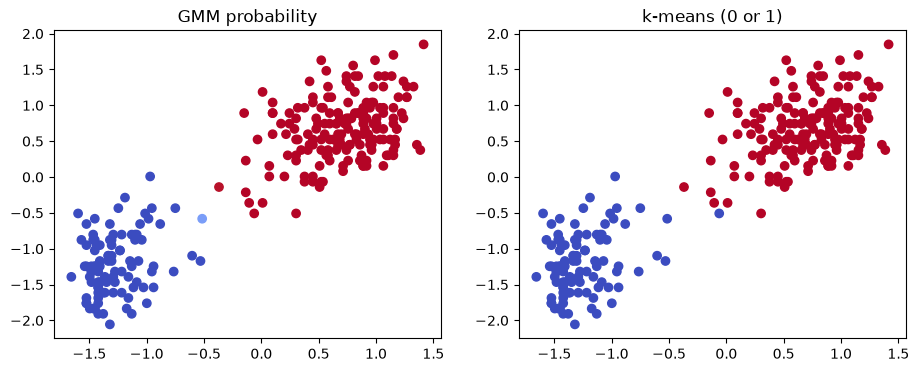

**확인 질문**
1. 파트 1 에서 시작 평균을 [140, 180] 으로 바꾸면 결과가 달라지나? [155, 155] 처럼 같게 두면?
2. 파트 1 의 로그 우도 그래프가 한 번이라도 내려가는가?
3. 파트 2 의 두 무리는 각각 몇 분쯤 기다리는가? 다음 분출을 기다리는 관광객에게 무엇이라고 말해 주겠나?
4. 파트 3 에서 GMM 이 애매하다고 한 점들은 그림의 어디에 있나? k-means 는 그 점들을 어떻게 다루나?

데이터 출처: Old Faithful geyser data (Azzalini & Bowman, 1990, Applied Statistics 39), seaborn-data 사본.